# 02 · Градиентный спуск и функции потерь

Четыре оптимизатора линейной регрессии реализованы в `mlproject/optimizers.py`: полный GD, minibatch SGD, Momentum и Adam. Сравнение идёт на тех же train/val/test Diabetes.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
while not (ROOT / 'mlproject').is_dir():
    if ROOT.parent == ROOT:
        raise RuntimeError('Open this notebook inside the project folder')
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
from IPython.display import display, Image
from mlproject.data import dataset, split
from mlproject.experiments import run


## Формулы и исправления

Для MSE градиент равен `2 Xᵀ(Xw − y) / n`. Для MAE используется знак невязки, для Huber — ограниченная невязка, для LogCosh — tanh. L2 не штрафует intercept и не изменяет веса во время вычисления градиента.

Для численной устойчивости LogCosh вычисляется через logaddexp. При повторном fit веса, состояния Adam/Momentum и история сбрасываются. Каждая функция потерь проверяется численным дифференцированием в tests.

Признаки и target стандартизируются статистиками только train. Предсказания переводятся обратно в исходные единицы перед расчётом RMSE.

In [2]:
results=run('02')
display(results.round(4))

,model,learning_rate,val_rmse,rmse,mae,r2
0,gd,0.03,51.1605,53.9870,43.0599,0.4499
1,sgd,0.03,51.1084,53.2585,42.5197,0.4646
2,momentum,0.01,51.1091,54.0505,42.9887,0.4486
3,adam,0.01,51.1292,54.0994,42.9667,0.4476


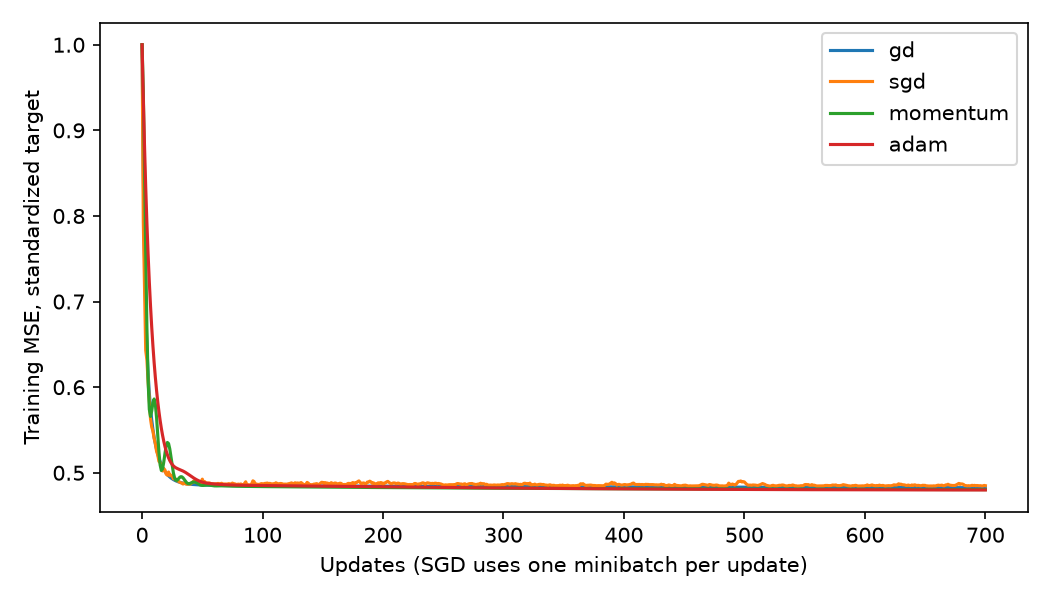

In [3]:
display(Image(filename=str(ROOT/'reports/02_optimization.png')))

## Робастные потери и L2

Дополнительный эксперимент сравнивает четыре потери при l2=0 и 0.1 только по validation; test для их выбора не используется.

In [4]:
display(pd.read_csv(ROOT/'reports/02_robust_losses.csv').round(4))

,loss,l2,val_rmse
0,mse,0.0,51.1920
1,mse,0.1,51.1710
2,mae,0.0,52.4871
3,mae,0.1,52.9994
4,huber,0.0,51.4445
5,huber,0.1,51.5195
6,logcosh,0.0,51.5611
7,logcosh,0.1,51.6669


In [5]:
best=results.sort_values('val_rmse').iloc[0]
print(f'Лучший оптимизатор по validation в этой сетке: {best.model}; test RMSE={best.rmse:.2f}.')

Лучший оптимизатор по validation в этой сетке: sgd; test RMSE=53.26.


## Ограничение сравнения

700 шагов SGD обрабатывают меньше примеров, чем 700 полных шагов GD. График показывает сходимость по обновлениям, а не доказанное преимущество по времени или одинаковому объёму вычислений.